# Premier League Match Prediction — All Models in One Notebook

**Purpose:** compare several match-outcome prediction approaches on the same historical Premier League dataset, with one shared feature set and chronological evaluation.

**Models included**
1. Prior-only `DummyClassifier` baseline
2. Balanced Logistic Regression
3. Random Forest
4. Extra Trees
5. Histogram Gradient Boosting
6. Independent Poisson goal model (predict home and away goals, then derive H/D/A probabilities)

**Important:** this is a historical benchmark, not a guarantee of future betting or match-prediction performance. The dataset ends in 2023. The final test seasons are held out until the final comparison.

## 1. Setup and data

Place `premier-league-matches.csv` in the same folder as this notebook. Required packages: `pandas`, `numpy`, `matplotlib`, `scikit-learn`, and `scipy`.

The target remains the original `FTR` convention: `H` = home win, `D` = draw, `A` = away win. Leading/trailing whitespace in `FTR` is stripped before validation.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import poisson
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
RESULT_CODES = ["H", "D", "A"]  # fixed order used for every probability metric
RESULT_NAMES = {"H": "Home win", "D": "Draw", "A": "Away win"}

DATA_PATH = Path("premier-league-matches.csv")
if not DATA_PATH.exists():
    # convenient fallback for the uploaded file location
    fallback = Path("/mnt/data/premier-league-matches.csv")
    if fallback.exists():
        DATA_PATH = fallback
    else:
        raise FileNotFoundError(
            "Cannot find premier-league-matches.csv. Put it beside this notebook."
        )

df = pd.read_csv(DATA_PATH)
print("File:", DATA_PATH.resolve())
print("Raw shape:", df.shape)
display(df.head())

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-cf684zco because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


File: /mnt/data/premier-league-matches.csv
Raw shape: (12026, 8)


,Season_End_Year,Wk,Date,Home,HomeGoals,AwayGoals,Away,FTR
0,1993,1,1992-08-15,Coventry City,2,1,Middlesbrough,H
1,1993,1,1992-08-15,Leeds United,2,1,Wimbledon,H
2,1993,1,1992-08-15,Sheffield Utd,2,1,Manchester Utd,H
3,1993,1,1992-08-15,Crystal Palace,3,3,Blackburn,D
4,1993,1,1992-08-15,Arsenal,2,4,Norwich City,A


## 2. Validate and prepare the dataset

This cell reports data-quality issues rather than silently deleting rows. `FTR` is normalized with `.str.strip()` to handle values such as `"A "` that should represent away wins.

In [2]:
REQUIRED = ["Season_End_Year", "Wk", "Date", "Home", "HomeGoals", "AwayGoals", "Away", "FTR"]
missing_cols = sorted(set(REQUIRED) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df[REQUIRED].copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
for col in ["Season_End_Year", "Wk", "HomeGoals", "AwayGoals"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in ["Home", "Away", "FTR"]:
    df[col] = df[col].astype("string").str.strip()

print("Missing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())
print("FTR values after trimming:")
display(df["FTR"].value_counts(dropna=False).rename_axis("FTR").to_frame("matches"))

bad_rows = df[ df[REQUIRED].isna().any(axis=1) | ~df["FTR"].isin(RESULT_CODES)
              | (df["HomeGoals"] < 0) | (df["AwayGoals"] < 0) ]
print("Rows with missing/invalid required values:", len(bad_rows))
exact_duplicates = int(df.duplicated().sum())
print("Exact duplicate rows:", exact_duplicates)

score_result = np.select(
    [df["HomeGoals"] > df["AwayGoals"], df["HomeGoals"] == df["AwayGoals"]],
    ["H", "D"], default="A"
)
disagreements = int((df["FTR"].notna() & (df["FTR"] != score_result)).sum())
print("FTR vs scoreline disagreements:", disagreements)

# Remove only rows that cannot be used by this supervised task; report the count.
before = len(df)
df = df.dropna(subset=REQUIRED).copy()
df = df[df["FTR"].isin(RESULT_CODES) & (df["HomeGoals"] >= 0) & (df["AwayGoals"] >= 0)].copy()
df = df.sort_values(["Date", "Season_End_Year", "Wk"], kind="stable").reset_index(drop=True)
print(f"Usable rows: {len(df):,} (excluded {before-len(df):,} invalid rows)")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Outcome counts:")
display(df["FTR"].value_counts().reindex(RESULT_CODES).rename(index=RESULT_NAMES).to_frame("matches"))

Missing values by column:


,missing_count
Season_End_Year,0
Wk,0
Date,0
Home,0
HomeGoals,0
AwayGoals,0
Away,0
FTR,0


FTR values after trimming:


,matches
FTR,
H,5519
A,3410
D,3097


Rows with missing/invalid required values: 0
Exact duplicate rows: 0
FTR vs scoreline disagreements: 0
Usable rows: 12,026 (excluded 0 invalid rows)
Date range: 1992-08-15 to 2023-05-28
Outcome counts:


,matches
FTR,
Home win,5519
Draw,3097
Away win,3410


## 3. Exploratory view

The class distribution helps interpret accuracy: a model can score reasonably by over-predicting the most frequent outcome. Macro F1 and balanced accuracy give equal weight to the three outcomes.

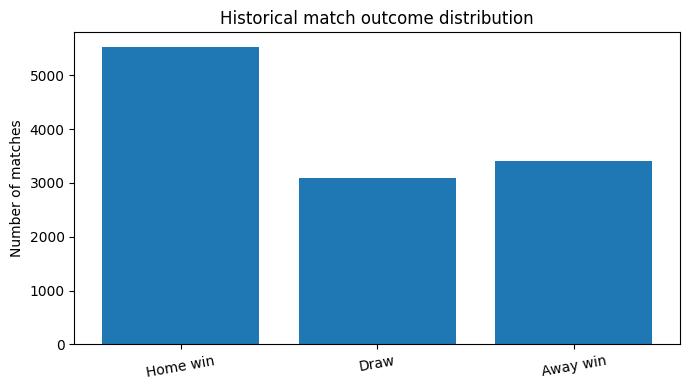

Most-frequent-class baseline accuracy: 0.4589


In [3]:
counts = df["FTR"].value_counts().reindex(RESULT_CODES, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([RESULT_NAMES[x] for x in RESULT_CODES], counts.values)
ax.set_title("Historical match outcome distribution")
ax.set_ylabel("Number of matches")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()
print("Most-frequent-class baseline accuracy:", round(counts.max() / counts.sum(), 4))

## 4. Leakage-aware pre-match features

For each team, features summarize its previous five appearances: goals for, goals against, and points. Separate home/away venue form is also included.

**Leakage safeguard:** match records are aggregated by team and calendar date, then shifted before rolling. Therefore, every match on a date uses form from dates strictly earlier than that date; no same-day result is allowed to enter its own features. Early-season missing history receives fixed, documented priors (1.35 goals for/against and 1 point per match).

In [4]:
def add_prematch_form_features(matches: pd.DataFrame, window: int = 5) -> pd.DataFrame:
    base = matches.copy().sort_values(["Date", "Season_End_Year", "Wk"], kind="stable")
    home_points = base["FTR"].map({"H": 3.0, "D": 1.0, "A": 0.0})
    away_points = base["FTR"].map({"H": 0.0, "D": 1.0, "A": 3.0})
    long = pd.concat([
        pd.DataFrame({"Team": base["Home"], "Date": base["Date"],
                      "GF": base["HomeGoals"], "GA": base["AwayGoals"],
                      "Points": home_points, "Venue": "home"}),
        pd.DataFrame({"Team": base["Away"], "Date": base["Date"],
                      "GF": base["AwayGoals"], "GA": base["HomeGoals"],
                      "Points": away_points, "Venue": "away"})
    ], ignore_index=True)

    cols = ["GF", "GA", "Points"]
    overall = long.groupby(["Team", "Date"], as_index=False)[cols].mean()
    overall = overall.sort_values(["Team", "Date"], kind="stable")
    for col in cols:
        overall[f"{col}_avg{window}"] = overall.groupby("Team", sort=False)[col].transform(
            lambda s: s.shift(1).rolling(window, min_periods=1).mean()
        )
    overall = overall[["Team", "Date"] + [f"{c}_avg{window}" for c in cols]]

    venue = long.groupby(["Team", "Venue", "Date"], as_index=False)[cols].mean()
    venue = venue.sort_values(["Team", "Venue", "Date"], kind="stable")
    for col in cols:
        venue[f"{col}_venue_avg{window}"] = venue.groupby(
            ["Team", "Venue"], sort=False
        )[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())
    venue = venue[["Team", "Venue", "Date"] + [f"{c}_venue_avg{window}" for c in cols]]

    priors = {f"{c}_avg{window}": v for c, v in
              [("GF", 1.35), ("GA", 1.35), ("Points", 1.0)]}
    venue_priors = {f"{c}_venue_avg{window}": v for c, v in
                    [("GF", 1.35), ("GA", 1.35), ("Points", 1.0)]}
    result = base.copy()
    for side, team_col, venue_name in [("home", "Home", "home"), ("away", "Away", "away")]:
        of = overall.rename(columns={"Team": team_col,
            **{c: f"{side}_{c.lower()}" for c in priors}})
        result = result.merge(of, on=[team_col, "Date"], how="left", validate="many_to_one")
        vf = venue[venue["Venue"] == venue_name].drop(columns="Venue").rename(
            columns={"Team": team_col,
                     **{c: f"{side}_{c.lower()}" for c in venue_priors}}
        )
        result = result.merge(vf, on=[team_col, "Date"], how="left", validate="many_to_one")
    for side in ["home", "away"]:
        for col, default in {**priors, **venue_priors}.items():
            name = f"{side}_{col.lower()}"
            result[name] = result[name].fillna(default)
    return result

model_df = add_prematch_form_features(df, window=5)
NUMERIC_FEATURES = [
    "home_gf_avg5", "home_ga_avg5", "home_points_avg5",
    "away_gf_avg5", "away_ga_avg5", "away_points_avg5",
    "home_gf_venue_avg5", "home_ga_venue_avg5", "home_points_venue_avg5",
    "away_gf_venue_avg5", "away_ga_venue_avg5", "away_points_venue_avg5",
]
CATEGORICAL_FEATURES = ["Home", "Away"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
assert model_df[FEATURES].isna().sum().sum() == 0
display(model_df[["Date", "Home", "Away", "FTR"] + NUMERIC_FEATURES[:4]].head())

,Date,Home,Away,FTR,home_gf_avg5,home_ga_avg5,home_points_avg5,away_gf_avg5
0,1992-08-15,Coventry City,Middlesbrough,H,1.35,1.35,1.0,1.35
1,1992-08-15,Leeds United,Wimbledon,H,1.35,1.35,1.0,1.35
2,1992-08-15,Sheffield Utd,Manchester Utd,H,1.35,1.35,1.0,1.35
3,1992-08-15,Crystal Palace,Blackburn,D,1.35,1.35,1.0,1.35
4,1992-08-15,Arsenal,Norwich City,A,1.35,1.35,1.0,1.35


## 5. Chronological train / validation / test split

Seasons are sorted and split into three consecutive blocks: roughly 70% train, 15% validation, and 15% test. The validation block is used to compare/select models. The test block is used only after all model definitions are fixed.

This is more realistic than a random split because future matches should not influence models evaluated on earlier matches.

In [5]:
seasons = np.array(sorted(model_df["Season_End_Year"].unique()))
if len(seasons) < 6:
    raise ValueError("Not enough distinct seasons for a chronological train/validation/test split.")
n = len(seasons)
train_end = max(1, int(np.floor(n * 0.70)))
valid_end = max(train_end + 1, int(np.floor(n * 0.85)))
valid_end = min(valid_end, n - 1)
train_seasons = seasons[:train_end]
valid_seasons = seasons[train_end:valid_end]
test_seasons = seasons[valid_end:]

train = model_df[model_df["Season_End_Year"].isin(train_seasons)].copy()
valid = model_df[model_df["Season_End_Year"].isin(valid_seasons)].copy()
test = model_df[model_df["Season_End_Year"].isin(test_seasons)].copy()

def split_summary(name, part):
    return {"split": name, "first_season": int(part["Season_End_Year"].min()),
            "last_season": int(part["Season_End_Year"].max()), "matches": len(part),
            "first_date": part["Date"].min().date(), "last_date": part["Date"].max().date()}
display(pd.DataFrame([split_summary("Train", train), split_summary("Validation", valid),
                      split_summary("Test", test)]))
X_train, y_train = train[FEATURES], train["FTR"]
X_valid, y_valid = valid[FEATURES], valid["FTR"]
X_test, y_test = test[FEATURES], test["FTR"]

,split,first_season,last_season,matches,first_date,last_date
0,Train,1993,2013,8226,1992-08-15,2013-05-19
1,Validation,2014,2018,1900,2013-08-17,2018-05-13
2,Test,2019,2023,1900,2018-08-10,2023-05-28


## 6. Define all classification models

All classifiers use the same features and the same chronological splits. Team names are one-hot encoded; numeric columns are median-imputed and standardized inside a pipeline, so preprocessing is learned from the training data only.

The tree models are included as alternatives to the linear logistic-regression model. They are not guaranteed to perform better, and their validation/test results should decide.

In [6]:
def make_preprocessor():
    return ColumnTransformer([
        ("teams", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("numbers", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), NUMERIC_FEATURES)
    ])

classifiers = {
    "Prior baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", C=1.0, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=180, learning_rate=0.08, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline([("prep", make_preprocessor()), ("model", estimator)])
    for name, estimator in classifiers.items()
}
print("Classification models:", ", ".join(pipelines))

Classification models: Prior baseline, Logistic Regression, Random Forest, Extra Trees, Hist Gradient Boosting


## 7. Metric functions and validation comparison

Metrics:
- **Accuracy:** fraction of exact outcomes predicted correctly.
- **Balanced accuracy:** average recall across H/D/A.
- **Macro F1:** average F1 across H/D/A; treats each outcome equally.
- **Log loss:** penalizes confident incorrect probabilities; lower is better.
- **Multiclass Brier score:** mean squared probability error over the three classes; lower is better.

Every probability matrix is explicitly reordered to `['H', 'D', 'A']` before calculating probability metrics. This avoids subtle class-order bugs.

In [7]:
def aligned_probabilities(model, X, labels=RESULT_CODES):
    raw = model.predict_proba(X)
    model_classes = list(model.classes_)
    return np.column_stack([
        raw[:, model_classes.index(label)] if label in model_classes else np.zeros(len(X))
        for label in labels
    ])

def score_predictions(y_true, y_pred, probabilities):
    one_hot = np.column_stack([(np.asarray(y_true) == label).astype(float)
                               for label in RESULT_CODES])
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=RESULT_CODES, average="macro", zero_division=0),
        "log_loss": float(-np.mean(np.log(np.clip(probabilities[np.arange(len(y_true)), [RESULT_CODES.index(v) for v in np.asarray(y_true)]], 1e-15, 1.0)))),
        "brier_score": float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))
    }

validation_rows = []
fitted_on_train = {}
for name, model in pipelines.items():
    start = __import__("time").perf_counter()
    model.fit(X_train, y_train)
    elapsed = __import__("time").perf_counter() - start
    pred = model.predict(X_valid)
    prob = aligned_probabilities(model, X_valid)
    row = {"model": name, **score_predictions(y_valid, pred, prob),
           "fit_seconds_train": elapsed}
    validation_rows.append(row)
    fitted_on_train[name] = model

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["macro_f1", "log_loss"], ascending=[False, True]
).reset_index(drop=True)
display(validation_results.round(4))

,model,accuracy,balanced_accuracy,macro_f1,log_loss,brier_score,fit_seconds_train
0,Logistic Regression,0.4800,0.4566,0.4544,1.0438,0.6246,4.4136
1,Extra Trees,0.4789,0.4423,0.4404,1.0299,0.6175,1.1201
2,Random Forest,0.4879,0.4350,0.4268,1.0260,0.6155,1.2627
3,Hist Gradient Boosting,0.4821,0.4107,0.3960,1.0373,0.6181,1.2555
4,Prior baseline,0.4568,0.3333,0.2091,1.0661,0.6439,0.0417


## 8. Poisson goal model

Instead of predicting H/D/A directly, this approach predicts home and away goal counts with two Poisson regressions. The two goal distributions are   treated as independent; their scoreline probabilities are combined into H/D/A probabilities.

This independence assumption is a simplification.It is included because goal-based modeling is a natural alternative, not because it must outperform the classifiers.

In [8]:
POISSON_FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

def poisson_feature_pipeline():
    return Pipeline([
        ("prep", make_preprocessor()),
        ("model", PoissonRegressor(alpha=0.5, max_iter=500))
    ])

def fit_poisson_goal_models(frame):
    X = frame[POISSON_FEATURES]
    home_model = poisson_feature_pipeline().fit(X, frame["HomeGoals"])
    away_model = poisson_feature_pipeline().fit(X, frame["AwayGoals"])
    return home_model, away_model

def poisson_outcome_probabilities(goal_models, X, max_goals=10):
    home_model, away_model = goal_models
    mu_home = np.clip(home_model.predict(X), 0.05, 8.0)
    mu_away = np.clip(away_model.predict(X), 0.05, 8.0)
    grid = np.arange(max_goals + 1)
    result = np.zeros((len(X), 3), dtype=float)  # H, D, A
    for i, (mh, ma) in enumerate(zip(mu_home, mu_away)):
        ph = poisson.pmf(grid, mh)
        pa = poisson.pmf(grid, ma)
        score_matrix = np.outer(ph, pa)
        result[i, 0] = np.tril(score_matrix, k=-1).sum()  # row(home goals) > col(away goals)
        result[i, 1] = np.trace(score_matrix)
        result[i, 2] = np.triu(score_matrix, k=1).sum()
    result = result / result.sum(axis=1, keepdims=True)
    return result

poisson_train_start = __import__("time").perf_counter()
poisson_train_models = fit_poisson_goal_models(train)
poisson_train_seconds = __import__("time").perf_counter() - poisson_train_start
poisson_valid_prob = poisson_outcome_probabilities(poisson_train_models, X_valid)
poisson_valid_pred = np.array(RESULT_CODES)[poisson_valid_prob.argmax(axis=1)]
poisson_validation_row = {"model": "Poisson goals", **score_predictions(y_valid, poisson_valid_pred, poisson_valid_prob),
                          "fit_seconds_train": poisson_train_seconds}
validation_results = pd.concat([validation_results, pd.DataFrame([poisson_validation_row])],
                               ignore_index=True).sort_values(
    ["macro_f1", "log_loss"], ascending=[False, True]
).reset_index(drop=True)
display(validation_results.round(4))

,model,accuracy,balanced_accuracy,macro_f1,log_loss,brier_score,fit_seconds_train
0,Logistic Regression,0.4800,0.4566,0.4544,1.0438,0.6246,4.4136
1,Extra Trees,0.4789,0.4423,0.4404,1.0299,0.6175,1.1201
2,Random Forest,0.4879,0.4350,0.4268,1.0260,0.6155,1.2627
3,Hist Gradient Boosting,0.4821,0.4107,0.3960,1.0373,0.6181,1.2555
4,Poisson goals,0.5132,0.4158,0.3574,1.0122,0.6049,1.0991
5,Prior baseline,0.4568,0.3333,0.2091,1.0661,0.6439,0.0417


## 9. Select on validation only, then evaluate every model on the held-out test seasons

Selection rule: highest validation macro F1, with validation log loss as the tie-breaker. This rule is for selecting one preferred model; the comparison below still reports **all** models. After selection, each classifier is refit on train + validation before test evaluation. The Poisson models are refit the same way.

Do not use test metrics to keep changing model settings; doing so would turn the test set into another validation set.

In [9]:
train_valid = pd.concat([train, valid], ignore_index=True)
X_train_valid, y_train_valid = train_valid[FEATURES], train_valid["FTR"]

test_rows = []
test_models = {}
for name, estimator in classifiers.items():
    model = Pipeline([("prep", make_preprocessor()), ("model", clone(estimator))])
    start = __import__("time").perf_counter()
    model.fit(X_train_valid, y_train_valid)
    elapsed = __import__("time").perf_counter() - start
    pred = model.predict(X_test)
    prob = aligned_probabilities(model, X_test)
    test_rows.append({"model": name, **score_predictions(y_test, pred, prob),
                      "fit_seconds_train_valid": elapsed})
    test_models[name] = model

poisson_test_start = __import__("time").perf_counter()
poisson_test_models = fit_poisson_goal_models(train_valid)
poisson_test_seconds = __import__("time").perf_counter() - poisson_test_start
poisson_test_prob = poisson_outcome_probabilities(poisson_test_models, X_test)
poisson_test_pred = np.array(RESULT_CODES)[poisson_test_prob.argmax(axis=1)]
test_rows.append({"model": "Poisson goals",
                  **score_predictions(y_test, poisson_test_pred, poisson_test_prob),
                  "fit_seconds_train_valid": poisson_test_seconds})

test_results = pd.DataFrame(test_rows).sort_values(
    ["macro_f1", "log_loss"], ascending=[False, True]
).reset_index(drop=True)
display(test_results.round(4))

# One side-by-side table makes it easy to compare validation performance with final test performance.
comparison = validation_results.merge(test_results, on="model", suffixes=("_validation", "_test"))
comparison = comparison.sort_values(
    ["macro_f1_validation", "log_loss_validation"], ascending=[False, True]
).reset_index(drop=True)
print("All models: validation metrics beside held-out test metrics")
display(comparison[[
    "model",
    "accuracy_validation", "macro_f1_validation", "log_loss_validation",
    "accuracy_test", "balanced_accuracy_test", "macro_f1_test",
    "log_loss_test", "brier_score_test"
]].round(4))

best_name = validation_results.iloc[0]["model"]
print("Selected using validation only:", best_name)
print("Validation macro F1:", round(float(validation_results.iloc[0]["macro_f1"]), 4))
print("Held-out test seasons:", int(test["Season_End_Year"].min()), "to",
      int(test["Season_End_Year"].max()))

,model,accuracy,balanced_accuracy,macro_f1,log_loss,brier_score,fit_seconds_train_valid
0,Extra Trees,0.4853,0.4517,0.4499,1.0284,0.6161,1.2714
1,Logistic Regression,0.4747,0.4442,0.4437,1.0357,0.6194,4.3115
2,Random Forest,0.4905,0.4373,0.4294,1.0246,0.6143,1.5526
3,Hist Gradient Boosting,0.5168,0.4249,0.3810,1.0039,0.5991,0.5463
4,Poisson goals,0.5163,0.4206,0.3662,1.0055,0.6008,0.9639
5,Prior baseline,0.4442,0.3333,0.2051,1.0708,0.6476,0.0717


All models: validation metrics beside held-out test metrics


,model,accuracy_validation,macro_f1_validation,log_loss_validation,accuracy_test,balanced_accuracy_test,macro_f1_test,log_loss_test,brier_score_test
0,Logistic Regression,0.4800,0.4544,1.0438,0.4747,0.4442,0.4437,1.0357,0.6194
1,Extra Trees,0.4789,0.4404,1.0299,0.4853,0.4517,0.4499,1.0284,0.6161
2,Random Forest,0.4879,0.4268,1.0260,0.4905,0.4373,0.4294,1.0246,0.6143
3,Hist Gradient Boosting,0.4821,0.3960,1.0373,0.5168,0.4249,0.3810,1.0039,0.5991
4,Poisson goals,0.5132,0.3574,1.0122,0.5163,0.4206,0.3662,1.0055,0.6008
5,Prior baseline,0.4568,0.2091,1.0661,0.4442,0.3333,0.2051,1.0708,0.6476


Selected using validation only: Logistic Regression
Validation macro F1: 0.4544
Held-out test seasons: 2019 to 2023


## 10. Side-by-side charts

These plots use the same held-out test set for every model. Accuracy and macro F1 are higher-is-better; log loss and Brier score are lower-is-better. Do not compare metrics from different split strategies as if they were equivalent.

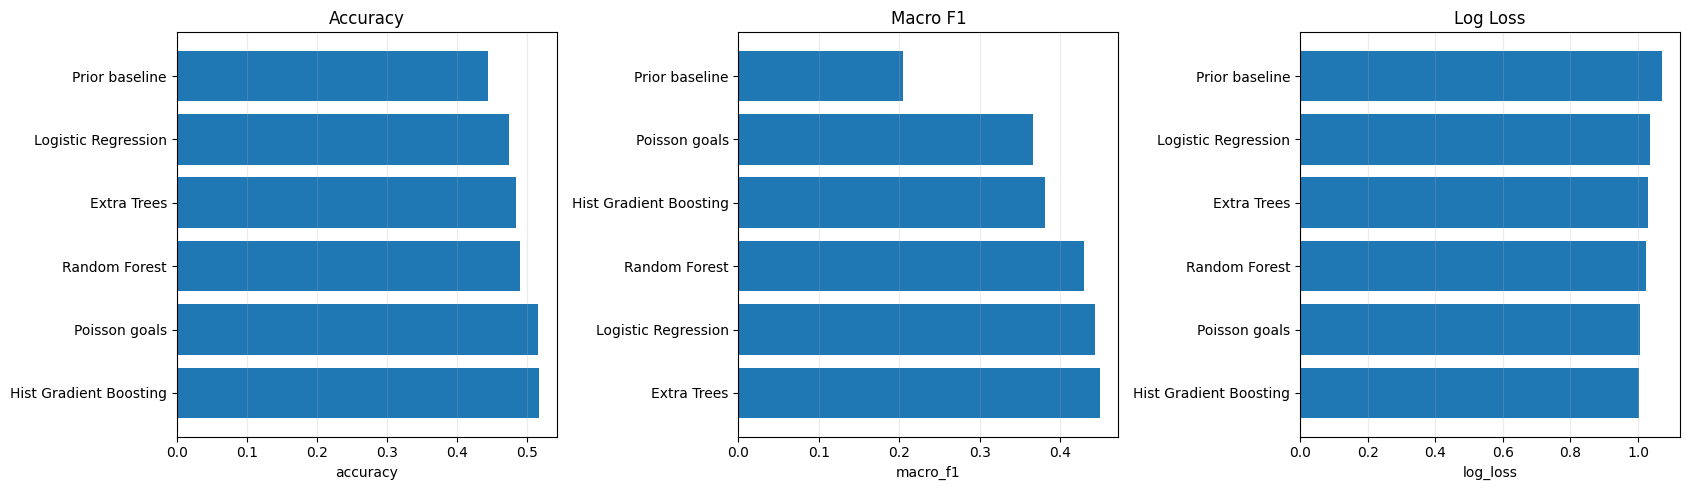

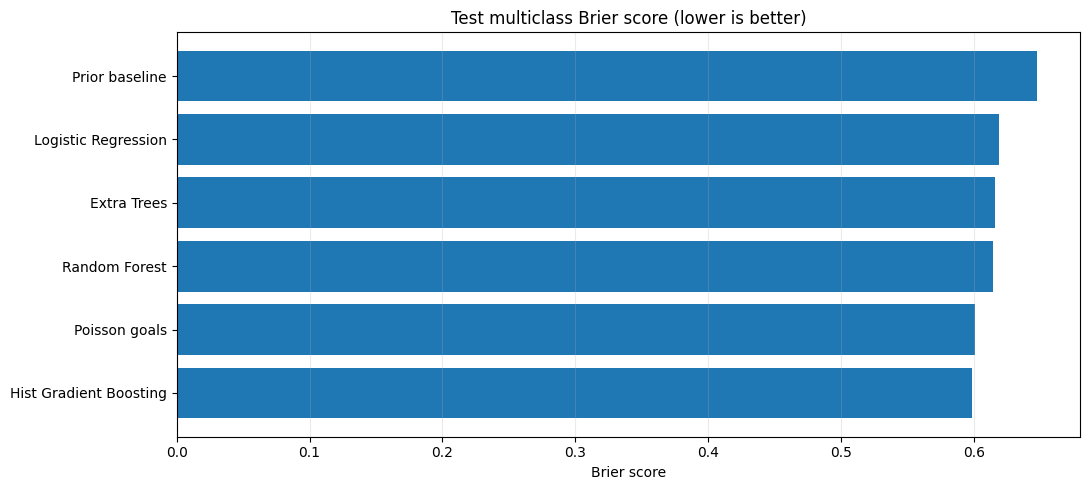

In [10]:
plot_metrics = ["accuracy", "balanced_accuracy", "macro_f1", "log_loss", "brier_score"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric in zip(axes, ["accuracy", "macro_f1", "log_loss"]):
    ordered = test_results.sort_values(metric, ascending=(metric == "log_loss"))
    ax.barh(ordered["model"], ordered[metric])
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel(metric)
    ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ordered = test_results.sort_values("brier_score")
ax.barh(ordered["model"], ordered["brier_score"])
ax.set_title("Test multiclass Brier score (lower is better)")
ax.set_xlabel("Brier score")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Confusion matrices and detailed report

The confusion matrix shows which outcomes are confused with each other. Rows are actual outcomes and columns are predicted outcomes, in the fixed order H, D, A.


Extra Trees
              precision    recall  f1-score   support

    Home win      0.588     0.557     0.572       844
        Draw      0.276     0.257     0.266       421
    Away win      0.485     0.542     0.512       635

    accuracy                          0.485      1900
   macro avg      0.450     0.452     0.450      1900
weighted avg      0.484     0.485     0.484      1900



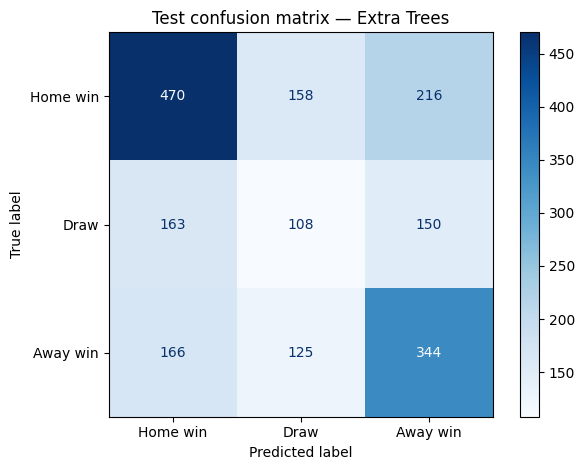


Logistic Regression
              precision    recall  f1-score   support

    Home win      0.599     0.539     0.568       844
        Draw      0.243     0.266     0.254       421
    Away win      0.492     0.528     0.509       635

    accuracy                          0.475      1900
   macro avg      0.445     0.444     0.444      1900
weighted avg      0.485     0.475     0.479      1900



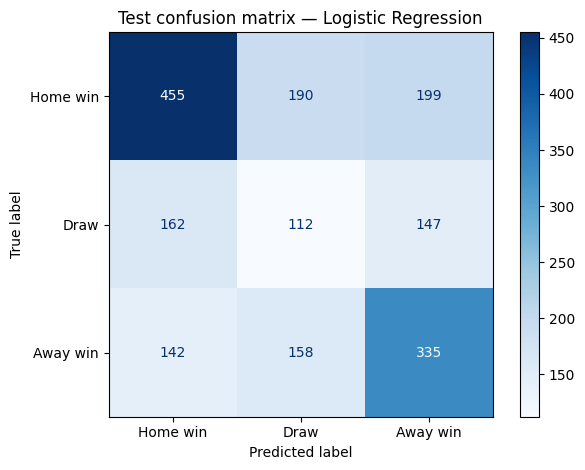


Random Forest
              precision    recall  f1-score   support

    Home win      0.569     0.624     0.595       844
        Draw      0.223     0.147     0.177       421
    Away win      0.494     0.540     0.516       635

    accuracy                          0.491      1900
   macro avg      0.428     0.437     0.429      1900
weighted avg      0.467     0.491     0.476      1900



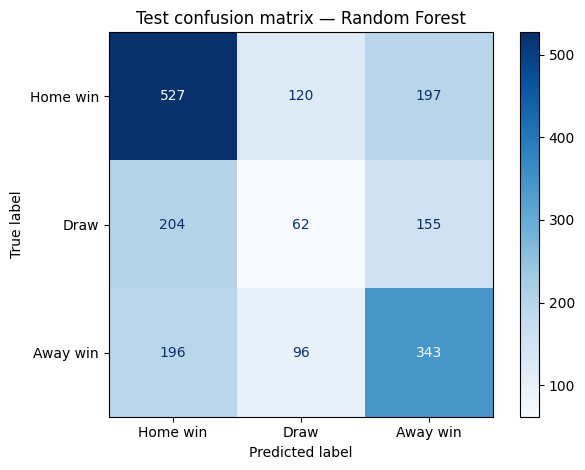


Hist Gradient Boosting
              precision    recall  f1-score   support

    Home win      0.519     0.847     0.644       844
        Draw      0.257     0.021     0.039       421
    Away win      0.530     0.406     0.460       635

    accuracy                          0.517      1900
   macro avg      0.435     0.425     0.381      1900
weighted avg      0.465     0.517     0.448      1900



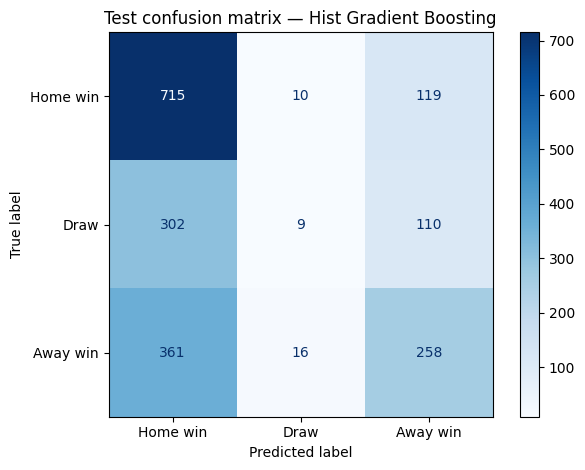


Poisson goals
              precision    recall  f1-score   support

    Home win      0.512     0.860     0.642       844
        Draw      0.000     0.000     0.000       421
    Away win      0.530     0.402     0.457       635

    accuracy                          0.516      1900
   macro avg      0.347     0.421     0.366      1900
weighted avg      0.404     0.516     0.438      1900



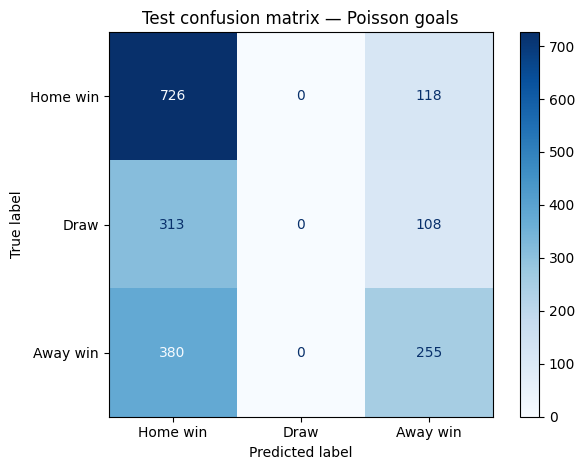


Prior baseline
              precision    recall  f1-score   support

    Home win      0.444     1.000     0.615       844
        Draw      0.000     0.000     0.000       421
    Away win      0.000     0.000     0.000       635

    accuracy                          0.444      1900
   macro avg      0.148     0.333     0.205      1900
weighted avg      0.197     0.444     0.273      1900



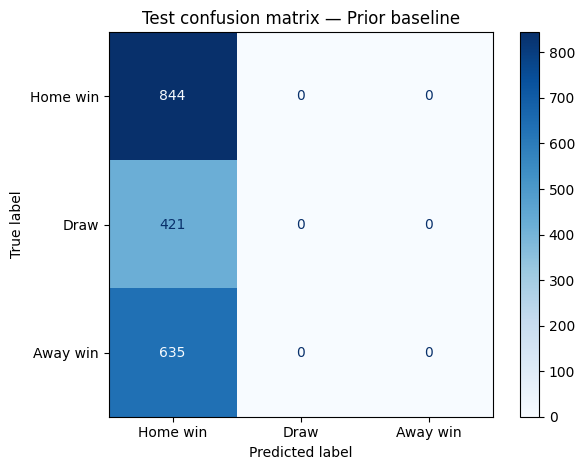

In [11]:
def predictions_for_test_model(name):
    if name == "Poisson goals":
        return poisson_test_pred, poisson_test_prob
    model = test_models[name]
    return model.predict(X_test), aligned_probabilities(model, X_test)

for name in test_results["model"]:
    pred, prob = predictions_for_test_model(name)
    print("\n" + "=" * 78)
    print(name)
    print(classification_report(y_test, pred, labels=RESULT_CODES,
                                target_names=[RESULT_NAMES[x] for x in RESULT_CODES],
                                zero_division=0, digits=3))
    cm = confusion_matrix(y_test, pred, labels=RESULT_CODES)
    disp = ConfusionMatrixDisplay(cm, display_labels=[RESULT_NAMES[x] for x in RESULT_CODES])
    disp.plot(values_format="d", cmap="Blues")
    plt.title(f"Test confusion matrix — {name}")
    plt.tight_layout()
    plt.show()

## 12. Inspect sample probabilities

The rows below show how each model distributes probability across home win, draw, and away win for a few held-out matches. Probabilities are estimates, not certainties.

In [12]:
sample_n = min(12, len(test))
sample = test.iloc[:sample_n][["Date", "Home", "Away", "HomeGoals", "AwayGoals", "FTR"]].copy()
sample["actual_outcome"] = sample["FTR"].map(RESULT_NAMES)
for name in test_results["model"]:
    _, prob = predictions_for_test_model(name)
    sample.loc[:, f"{name} — P(H)"] = prob[:sample_n, 0]
    sample.loc[:, f"{name} — P(D)"] = prob[:sample_n, 1]
    sample.loc[:, f"{name} — P(A)"] = prob[:sample_n, 2]
display(sample.round(3))

,Date,Home,Away,HomeGoals,AwayGoals,FTR,actual_outcome,Extra Trees — P(H),Extra Trees — P(D),Extra Trees — P(A),Logistic Regression — P(H),Logistic Regression — P(D),Logistic Regression — P(A),Random Forest — P(H),Random Forest — P(D),Random Forest — P(A),Hist Gradient Boosting — P(H),Hist Gradient Boosting — P(D),Hist Gradient Boosting — P(A),Poisson goals — P(H),Poisson goals — P(D),Poisson goals — P(A),Prior baseline — P(H),Prior baseline — P(D),Prior baseline — P(A)
10126,2018-08-10,Manchester Utd,Leicester City,2,1,H,Home win,0.554,0.309,0.137,0.629,0.257,0.115,0.537,0.315,0.148,0.716,0.181,0.102,0.578,0.228,0.194,0.462,0.264,0.274
10127,2018-08-11,Newcastle Utd,Tottenham,1,2,A,Away win,0.282,0.334,0.384,0.307,0.323,0.370,0.269,0.346,0.384,0.406,0.257,0.337,0.393,0.260,0.348,0.462,0.264,0.274
10128,2018-08-11,Bournemouth,Cardiff City,2,0,H,Home win,0.381,0.355,0.264,0.455,0.318,0.227,0.342,0.436,0.222,0.457,0.310,0.233,0.488,0.255,0.257,0.462,0.264,0.274
10129,2018-08-11,Fulham,Crystal Palace,0,2,A,Away win,0.247,0.262,0.491,0.238,0.320,0.442,0.229,0.261,0.509,0.305,0.248,0.446,0.308,0.259,0.433,0.462,0.264,0.274
10130,2018-08-11,Huddersfield,Chelsea,0,3,A,Away win,0.212,0.229,0.559,0.128,0.249,0.623,0.253,0.242,0.505,0.342,0.177,0.481,0.343,0.272,0.385,0.462,0.264,0.274
10131,2018-08-11,Watford,Brighton,2,0,H,Home win,0.380,0.396,0.224,0.382,0.408,0.210,0.417,0.393,0.189,0.528,0.253,0.219,0.521,0.250,0.228,0.462,0.264,0.274
10132,2018-08-11,Wolves,Everton,2,2,D,Draw,0.223,0.335,0.442,0.167,0.325,0.508,0.214,0.326,0.460,0.322,0.273,0.405,0.296,0.262,0.442,0.462,0.264,0.274
10133,2018-08-12,Southampton,Burnley,0,0,D,Draw,0.426,0.299,0.276,0.468,0.322,0.210,0.392,0.292,0.315,0.553,0.225,0.222,0.457,0.260,0.283,0.462,0.264,0.274
10134,2018-08-12,Liverpool,West Ham,4,0,H,Home win,0.526,0.338,0.135,0.591,0.298,0.111,0.555,0.287,0.158,0.642,0.245,0.113,0.668,0.195,0.137,0.462,0.264,0.274
10135,2018-08-12,Arsenal,Manchester City,0,2,A,Away win,0.298,0.427,0.275,0.410,0.344,0.246,0.303,0.350,0.347,0.437,0.271,0.292,0.427,0.248,0.325,0.462,0.264,0.274


## 13. Interpretation and limitations

- Prefer the model that performs well across several metrics, not just accuracy.
- If a model wins on validation but performs poorly on test, that is a sign of limited generalization or model-selection noise.
- Draw prediction is intrinsically difficult; inspect draw recall and calibration rather than hiding it inside overall accuracy.
- The Poisson model assumes independent home/away goal counts and truncates the score grid at 10 goals per side; the remaining tail probability is very small for ordinary football score rates, but the assumption is still an approximation.
- Historical form is calculated with same-date leakage protection, but it does not include lineups, injuries, transfers, bookmaker odds, or other potentially informative pre-match variables.
- The latest season in this file is 2022–23. These scores do not validate predictions on newer seasons.
- To make stronger claims, use rolling-origin evaluation over multiple season blocks and tune hyperparameters using only earlier data.

### Reproducibility

All models use `RANDOM_STATE = 42` where applicable. The notebook does not use random train/test splitting. It reports test results for all models, but chooses a preferred model based only on validation macro F1 and validation log loss.